# Monitoramento de preços de notebooks por API

**Faculdade:** Unifor\
**Disciplina:** F105 — Datamining e Web Scraping    
**Categoria:** Notebooks  
**Método de coleta:** API SerpApi com mecanismo Google Shopping\

**Equipe**: \
Ezequias Pereira Sousa – 2523533 \
Eduardo Medeiros Alencar Holanda - 2523614 \
Nataniel Miranda da Silva - 2523548 \
Pedro Enrique de Souza Simões - 2513694 \
Renata Lima lira - 2425231



## 1. Problema de mercado e objetivo

### Pergunta de negócio inicial

**Qual é a faixa de preço mais comum dos notebooks coletados e quais produtos apresentam os menores preços?**

### Objetivo

Construir um pipeline de dados que realize as etapas:

- **coleta → armazenamento → limpeza → transformação → análise → visualização → geração de insights**


## 2. Fonte de dados escolhida

A fonte de acesso escolhida é a **SerpApi**, utilizando o mecanismo **Google Shopping**. A SerpApi fornece uma resposta estruturada em JSON para consultas de produtos e ofertas.

É importante diferenciar os papéis de cada elemento:

| Elemento | Função no projeto |
|---|---|
| Google Shopping | Origem dos resultados de ofertas apresentados nas consultas |
| SerpApi | API utilizada para consultar os resultados em formato estruturado |
| Google Colab | Ambiente para executar o notebook |
| Python | Linguagem utilizada na coleta e na análise |
| Pandas | Organização, limpeza e tratamento dos dados |
| Matplotlib e Seaborn | Criação das visualizações |

A escolha da API ocorre porque muitas lojas comerciais utilizam carregamento dinâmico, limitações de requisições e mecanismos de proteção contra Web Scraping direto. A API reduz a dependência da estrutura HTML individual de cada loja e permite consultar os resultados de maneira padronizada.

A SerpApi exige cadastro e chave de autenticação. O plano gratuito, quando disponível para a conta utilizada, possui limites de uso. A chave não será escrita diretamente no notebook compartilhado.

## 3. Justificativa: API em vez de Web Scraping direto

A proposta oficial permite utilizar Web Scraping, APIs públicas ou uma combinação das técnicas. Neste projeto, optou-se pela API porque ela apresenta maior viabilidade técnica para uma coleta acadêmica limitada.

O Web Scraping direto exigiria acessar páginas de diferentes lojas, analisar o HTML de cada uma e criar seletores específicos para nome, preço e URL. Como cada loja possui uma estrutura própria, os seletores poderiam deixar de funcionar quando a página fosse modificada. Além disso, parte dos preços pode ser carregada por JavaScript ou protegida contra acessos automatizados.

A SerpApi retorna os resultados em JSON, facilitando a identificação dos campos de produto, preço, fonte comercial e link. Isso não elimina o tratamento de dados: ainda será necessário verificar ausências, duplicidades, preços, URLs e diferenças entre lojas.

A utilização da API será limitada ao objetivo acadêmico. Não serão feitas tentativas de contornar CAPTCHA, login, mecanismos de segurança ou limites de uso.

## 4. Campos planejados

| Campo | Descrição | Obrigatório |
|---|---|---|
| `nome_produto` | Título ou nome da oferta | Sim |
| `preco_bruto` | Preço preservado como retornado pela API | Sim |
| `loja` | Fonte comercial exibida pela API | Sim, quando disponível |
| `url` | Link da oferta ou do produto | Sim, quando disponível |
| `categoria` | Termo utilizado na consulta | Sim |
| `preco_numerico_api` | Preço numérico retornado pela API, quando disponível | Opcional |
| `preco_anterior` | Preço anterior, quando disponível | Opcional |
| `avaliacao` | Avaliação, quando disponível | Opcional |
| `quantidade_avaliacoes` | Número de avaliações, quando disponível | Opcional |
| `data_coleta` | Data e horário da consulta | Sim |
| `id_produto` | Identificador retornado pela API, quando disponível | Opcional |

Os campos opcionais somente serão preenchidos se existirem na resposta real.

## 5. Análise da estrutura da fonte

Como a estratégia escolhida é uma API, a estrutura analisada será a resposta JSON, e não o HTML de uma loja específica. Após a consulta de teste, serão examinadas as chaves principais e o conteúdo do campo que contém os resultados.

Os caminhos dos campos somente serão considerados confirmados depois de aparecerem na resposta real. Um exemplo possível, a ser validado, é:

```python
dados["shopping_results"][0]["title"]
dados["shopping_results"][0]["price"]
dados["shopping_results"][0]["source"]
dados["shopping_results"][0]["product_link"]
```

Como a coleta não será realizada diretamente pelo HTML das lojas, não serão inventados seletores CSS ou XPath. No relatório, será documentado o endpoint, os parâmetros e os caminhos JSON efetivamente usados.

In [ ]:
# Instalação e importação das bibliotecas
!pip -q install requests pandas numpy matplotlib seaborn

import os
import re
import json
import time
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime
from getpass import getpass
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

print("Ambiente configurado com sucesso.")
print("Pandas:", pd.__version__)

Ambiente configurado com sucesso.
Pandas: 2.2.3


In [ ]:
# Criação de pastas no ambiente do Colab
PASTA_PROJETO = "/content/projeto_notebooks"
PASTA_BRUTOS = f"{PASTA_PROJETO}/dados_brutos"
PASTA_TRATADOS = f"{PASTA_PROJETO}/dados_tratados"
PASTA_GRAFICOS = f"{PASTA_PROJETO}/graficos"
PASTA_SAIDAS = f"{PASTA_PROJETO}/saidas"

for pasta in [PASTA_PROJETO, PASTA_BRUTOS, PASTA_TRATADOS, PASTA_GRAFICOS, PASTA_SAIDAS]:
    os.makedirs(pasta, exist_ok=True)

print("Pastas criadas:")
for pasta in [PASTA_PROJETO, PASTA_BRUTOS, PASTA_TRATADOS, PASTA_GRAFICOS, PASTA_SAIDAS]:
    print(pasta)

Pastas criadas:
/content/projeto_notebooks
/content/projeto_notebooks/dados_brutos
/content/projeto_notebooks/dados_tratados
/content/projeto_notebooks/graficos
/content/projeto_notebooks/saidas


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 6. Inserção segura da chave da API

A chave da SerpApi não deve ser digitada diretamente no código, pois o notebook poderá ser compartilhado. A célula seguinte solicita a chave sem exibi-la na tela.

Para obter a chave, acesse o painel da sua conta em [serpapi.com](https://serpapi.com/). Não compartilhe a chave no relatório, no vídeo ou em um notebook público.

In [ ]:
# Inserção segura da chave da API
SERPAPI_KEY = getpass("Cole sua chave da SerpApi e pressione Enter: ")

if not SERPAPI_KEY:
    raise ValueError("A chave da SerpApi não foi informada.")

print("Chave recebida. O conteúdo não será exibido.")

Cole sua chave da SerpApi e pressione Enter: ··········
Chave recebida. O conteúdo não será exibido.


In [ ]:
# Consulta de teste para verificar acesso e estrutura da resposta
PARAMETROS_TESTE = {
    "engine": "google_shopping",
    "q": "notebook",
    "location": "Brazil",
    "gl": "br",
    "hl": "pt",
    "num": 40,
    "api_key": SERPAPI_KEY
}

resposta_teste = requests.get(
    "https://serpapi.com/search.json",
    params=PARAMETROS_TESTE,
    timeout=30
)

print("Código HTTP:", resposta_teste.status_code)

if resposta_teste.status_code != 200:
    print(resposta_teste.text[:1500])
    raise RuntimeError("A consulta de teste falhou. Verifique a chave e o limite da conta.")

dados_teste = resposta_teste.json()
print("Chaves principais:", list(dados_teste.keys()))
print("Quantidade de resultados:", len(dados_teste.get("shopping_results", [])))

Código HTTP: 200
Chaves principais: ['search_metadata', 'search_parameters', 'search_information', 'shopping_results', 'filters']
Quantidade de resultados: 40


In [ ]:
# Inspeção dos campos reais retornados pela API
resultados_teste = dados_teste.get("shopping_results", [])

if not resultados_teste:
    raise ValueError("A resposta não possui shopping_results. Será necessário investigar a resposta real.")

print("Campos do primeiro resultado:")
print(sorted(resultados_teste[0].keys()))

print("\nPrimeiro resultado completo:")
print(json.dumps(resultados_teste[0], indent=2, ensure_ascii=False)[:4000])

Campos do primeiro resultado:
['extracted_price', 'immersive_product_page_token', 'position', 'price', 'product_id', 'product_link', 'rating', 'reviews', 'second_hand_condition', 'serpapi_immersive_product_api', 'serpapi_thumbnail', 'serpapi_thumbnails', 'source', 'source_icon', 'thumbnail', 'thumbnails', 'title']

Primeiro resultado completo:
{
  "position": 1,
  "title": "Notebook Positivo Vision C15M Intel Celeron N4500 Windows 11 Home 4GB RAM 128GB eMMC Tela 15\" Full HD IPS Antirreflexo - Minitela e Tecla Copilot -",
  "product_id": "9470419649217607254",
  "product_link": "https://www.google.com/search?ibp=oshop&q=notebook&prds=productid:9470419649217607254,headlineOfferDocid:9470419649217607254,imageDocid:8237008492857687354,rds:PC_18430419983914310320|PROD_PC_18430419983914310320,pvt:hg&hl=pt&gl=br&udm=28",
  "immersive_product_page_token": "WopXuHicdZTJrrPYEccT5QXyCHffup8OGAx8V14wG8xgOHAYNojRmNkYDEZ5mNbtQeksO4u8QF6ie5HnyDJuJcoqKenU4vz1V5Wqfqp__O6Pn_n1b56Qg_jWaooSXbGcPrehqQMr-G

## 7. Estratégia de coleta

A consulta será realizada para o termo `notebook`, no contexto de resultados de compras do Brasil. A quantidade solicitada será de até 40 resultados por requisição, respeitando os limites da conta.

A coleta será considerada válida quando os registros possuírem nome, preço e URL ou identificador da oferta. Os registros serão preservados inicialmente em formato próximo ao retorno original. Depois será verificado se existem pelo menos 30 registros válidos.

A API não será consultada em grande escala. A coleta será limitada ao necessário para a atividade.

In [ ]:
# Função para executar uma consulta à API

def consultar_serpapi(termo, quantidade=40):
    parametros = {
        "engine": "google_shopping",
        "q": termo,
        "location": "Brazil",
        "gl": "br",
        "hl": "pt",
        "num": quantidade,
        "api_key": SERPAPI_KEY
    }
    resposta = requests.get(
        "https://serpapi.com/search.json",
        params=parametros,
        timeout=30
    )
    resposta.raise_for_status()
    return resposta.json()

# Coleta principal
TERMO_CONSULTA = "notebook"
data_coleta = datetime.now().isoformat(timespec="seconds")
dados_api = consultar_serpapi(TERMO_CONSULTA, quantidade=40)

# Preserva a resposta original antes de qualquer tratamento
arquivo_json_bruto = f"{PASTA_BRUTOS}/resposta_api_bruta.json"
with open(arquivo_json_bruto, "w", encoding="utf-8") as arquivo:
    json.dump(dados_api, arquivo, ensure_ascii=False, indent=2)

resultados_api = dados_api.get("shopping_results", [])
print("Resposta original salva em:", arquivo_json_bruto)
print("Resultados retornados:", len(resultados_api))

Resposta original salva em: /content/projeto_notebooks/dados_brutos/resposta_api_bruta.json
Resultados retornados: 40


In [ ]:
# Funções auxiliares para extrair campos

def primeiro_valor(registro, chaves):
    for chave in chaves:
        valor = registro.get(chave)
        if valor not in [None, "", []]:
            return valor
    return None


def extrair_valor_preco(registro):
    preco = registro.get("extracted_price")
    if preco not in [None, ""]:
        return preco
    preco_texto = registro.get("price")
    if isinstance(preco_texto, (int, float)):
        return preco_texto
    return None


# Transformação mínima: extração dos campos, sem limpeza dos textos
linhas_brutas = []
for registro in resultados_api:
    linhas_brutas.append({
        "nome_produto": primeiro_valor(registro, ["title", "name"]),
        "preco_bruto": registro.get("price"),
        "preco_numerico_api": extrair_valor_preco(registro),
        "loja": primeiro_valor(registro, ["source", "seller"]),
        "url": primeiro_valor(registro, ["product_link", "link"]),
        "preco_anterior": primeiro_valor(registro, ["old_price", "extracted_old_price"]),
        "avaliacao": registro.get("rating"),
        "quantidade_avaliacoes": registro.get("reviews"),
        "id_produto": registro.get("product_id"),
        "categoria": TERMO_CONSULTA,
        "data_coleta": data_coleta
    })

dados_brutos = pd.DataFrame(linhas_brutas)

print("Registros extraídos:", len(dados_brutos))
display(dados_brutos.head(40))

Registros extraídos: 40


,nome_produto,preco_bruto,preco_numerico_api,loja,url,preco_anterior,avaliacao,quantidade_avaliacoes,id_produto,categoria,data_coleta
0,"Notebook Positivo Vision C15M Intel Celeron N4500 Windows 11 Home 4GB RAM 128GB eMMC Tela 15"" Full HD IPS Antirrefle...","R$ 1.700,00",1700.00,mercadolivre.com.br,"https://www.google.com/search?ibp=oshop&q=notebook&prds=productid:9470419649217607254,headlineOfferDocid:94704196492...",None,3.1,161.0,9470419649217607254,notebook,2026-09-23T20:32:25
1,"Lenovo V15 G5 IRL Intel Core i3 i3-1315U Laptop 39,6 cm (15.6"") Full HD 16 GB DDR5-SDRAM 512 GB SSD Wi-Fi 6 (802.11a...","R$ 6.909,00",6909.00,Pontofrio.com,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:9096859369443801621,productid:12152459025068106131...",None,3.4,1.0,9096859369443801621,notebook,2026-09-23T20:32:25
2,Notebook Acer Aspire 3 Intel Core I3 8GB 256GB SSD,"R$ 4.999,90 agora",4999.90,Havan,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:5469460162370479879,productid:14636892844641066743...",None,5.0,102.0,5469460162370479879,notebook,2026-09-23T20:32:25
3,"Notebook Acer Nitro V15 ANV15-52-56PD Nvidia RTX 4050 Intel Core i5-13420H 15.6"" 8GB 512GB SSD Windows 11 Home","R$ 7.400,00",7400.00,mercadolivre.com.br,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:16327307819868325986,productid:5419231045841424138...",None,4.9,1.0,16327307819868325986,notebook,2026-09-23T20:32:25
4,Samsung Galaxy Book4 Intel Inside U300 Windows 11 Home 8GB,"R$ 3.059,10 agora",3059.10,Magalu,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:1309346349018073886,productid:9543514090101992912,...",None,5.0,75.0,1309346349018073886,notebook,2026-09-23T20:32:25
5,Notebook Lenovo IdeaPad 1i Celeron 4GB 128GB SSD Windows 11,"R$ 1.499,01",1499.01,Saldão da Informática,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:11747556153020388972,productid:1608688014781160675...",None,5.0,5.0,11747556153020388972,notebook,2026-09-23T20:32:25
6,Notebook Lenovo IdeaPad 1i Core i3-1315U 8GB 256GB SSD Windows 11,"R$ 6.203,57 agora",6203.57,Magalu,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:803456426879184696,productid:9903805084251100559,h...",None,4.2,101.0,803456426879184696,notebook,2026-09-23T20:32:25
7,Notebook Positivo Vision C15M Intel Celeron N4500 8GB RAM eMMC IPS,"R$ 2.999,90 agora",2999.90,Havan,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:17339163285976794031,productid:1359980401880069686...",None,3.8,168.0,17339163285976794031,notebook,2026-09-23T20:32:25
8,Notebook Positivo Vision R15M AMD Ryzen 3-7330U 8GB RAM SSD Wi-Fi 6 15” Full HD IPS,"R$ 4.364,00 agora",4364.00,eFácil,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:906918910872843665,productid:17735974452723901572,...",None,3.3,19.0,906918910872843665,notebook,2026-09-23T20:32:25
9,Notebook Lenovo IdeaPad Slim 3 15IRU10 Intel Core 3 100U 8GB 512GB SSD,"R$ 3.571,05 agora",3571.05,KaBuM!,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:6325282425062420881,productid:13980830052416673562...",None,5.0,1.0,6325282425062420881,notebook,2026-09-23T20:32:25


In [ ]:
# Validação inicial dos registros
colunas_obrigatorias = ["nome_produto", "preco_bruto", "categoria"]

for coluna in colunas_obrigatorias:
    if coluna not in dados_brutos.columns:
        raise ValueError(f"Coluna obrigatória ausente: {coluna}")

validos = dados_brutos[
    dados_brutos["nome_produto"].notna() &
    dados_brutos["preco_bruto"].notna()
].copy()

print("Registros extraídos:", len(dados_brutos))
print("Registros com nome e preço:", len(validos))
print("Lojas/fontes diferentes:", validos["loja"].dropna().nunique())

if len(validos) < 30:
    print("ATENÇÃO: ainda não há 30 registros válidos. Não serão inventados registros.")
else:
    print("A meta mínima de 30 registros foi atingida nesta consulta.")

if validos["loja"].dropna().nunique() < 2:
    print("ATENÇÃO: há menos de duas lojas/fontes. A pergunta sobre menor preço médio por loja poderá precisar ser adaptada.")

Registros extraídos: 40
Registros com nome e preço: 40
Lojas/fontes diferentes: 21
A meta mínima de 30 registros foi atingida nesta consulta.


In [ ]:
# Salvamento dos dados brutos antes da limpeza
arquivo_bruto_csv = f"{PASTA_BRUTOS}/dados_brutos.csv"
dados_brutos.to_csv(arquivo_bruto_csv, index=False, encoding="utf-8-sig")

print("Arquivo de dados brutos salvo em:", arquivo_bruto_csv)
display(pd.read_csv(arquivo_bruto_csv).head())

Arquivo de dados brutos salvo em: /content/projeto_notebooks/dados_brutos/dados_brutos.csv


,nome_produto,preco_bruto,preco_numerico_api,loja,url,preco_anterior,avaliacao,quantidade_avaliacoes,id_produto,categoria,data_coleta
0,"Notebook Positivo Vision C15M Intel Celeron N4500 Windows 11 Home 4GB RAM 128GB eMMC Tela 15"" Full HD IPS Antirrefle...","R$ 1.700,00",1700.0,mercadolivre.com.br,"https://www.google.com/search?ibp=oshop&q=notebook&prds=productid:9470419649217607254,headlineOfferDocid:94704196492...",NaN,3.1,161.0,9470419649217607254,notebook,2026-09-23T20:32:25
1,"Lenovo V15 G5 IRL Intel Core i3 i3-1315U Laptop 39,6 cm (15.6"") Full HD 16 GB DDR5-SDRAM 512 GB SSD Wi-Fi 6 (802.11a...","R$ 6.909,00",6909.0,Pontofrio.com,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:9096859369443801621,productid:12152459025068106131...",NaN,3.4,1.0,9096859369443801621,notebook,2026-09-23T20:32:25
2,Notebook Acer Aspire 3 Intel Core I3 8GB 256GB SSD,"R$ 4.999,90 agora",4999.9,Havan,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:5469460162370479879,productid:14636892844641066743...",NaN,5.0,102.0,5469460162370479879,notebook,2026-09-23T20:32:25
3,"Notebook Acer Nitro V15 ANV15-52-56PD Nvidia RTX 4050 Intel Core i5-13420H 15.6"" 8GB 512GB SSD Windows 11 Home","R$ 7.400,00",7400.0,mercadolivre.com.br,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:16327307819868325986,productid:5419231045841424138...",NaN,4.9,1.0,16327307819868325986,notebook,2026-09-23T20:32:25
4,Samsung Galaxy Book4 Intel Inside U300 Windows 11 Home 8GB,"R$ 3.059,10 agora",3059.1,Magalu,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:1309346349018073886,productid:9543514090101992912,...",NaN,5.0,75.0,1309346349018073886,notebook,2026-09-23T20:32:25


## 8. Importação dos dados pelo Google Drive

O Colab possui um ambiente temporário. Para preservar os arquivos, podemos montar o Google Drive e copiar os resultados para uma pasta permanente.

Execute a célula seguinte e autorize o acesso quando o Google solicitar. Depois, ajuste o nome da pasta se necessário.

In [ ]:
# Montagem do Google Drive
from google.colab import drive

drive.mount("/content/drive")

PASTA_DRIVE = "/content/drive/MyDrive/projeto_notebooks"
os.makedirs(f"{PASTA_DRIVE}/dados_brutos", exist_ok=True)
os.makedirs(f"{PASTA_DRIVE}/dados_tratados", exist_ok=True)
os.makedirs(f"{PASTA_DRIVE}/graficos", exist_ok=True)
os.makedirs(f"{PASTA_DRIVE}/saidas", exist_ok=True)

print("Google Drive montado.")
print("Pasta do projeto:", PASTA_DRIVE)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive montado.
Pasta do projeto: /content/drive/MyDrive/projeto_notebooks


In [ ]:
# Cópia dos dados brutos e da resposta JSON para o Google Drive
import shutil

shutil.copy2(arquivo_json_bruto, f"{PASTA_DRIVE}/dados_brutos/resposta_api_bruta.json")
shutil.copy2(arquivo_bruto_csv, f"{PASTA_DRIVE}/dados_brutos/dados_brutos.csv")

print("Dados brutos copiados para o Google Drive.")

Dados brutos copiados para o Google Drive.


## 9. Pré-processamento

Nesta etapa serão verificados valores ausentes, duplicidades, espaços extras, URLs, nomes e preços.

O preço será convertido para um número quando a API não tiver fornecido um valor numérico. A conversão considera formatos como `R$ 2.499,90`, `2,499.90` e outros formatos textuais. A regra será aplicada somente aos valores que puderem ser interpretados.

In [ ]:
# Diagnóstico inicial de qualidade
print("Valores ausentes por coluna:")
display(dados_brutos.isna().sum().to_frame("quantidade_ausente"))

print("Quantidade de registros duplicados completos:", dados_brutos.duplicated().sum())
print("Quantidade de URLs duplicadas:", dados_brutos["url"].duplicated().sum())

Valores ausentes por coluna:


,quantidade_ausente
nome_produto,0
preco_bruto,0
preco_numerico_api,0
loja,0
url,0
preco_anterior,40
avaliacao,8
quantidade_avaliacoes,8
id_produto,0
categoria,0


Quantidade de registros duplicados completos: 0
Quantidade de URLs duplicadas: 0


In [ ]:
# Funções de limpeza

def limpar_texto(valor):
    if pd.isna(valor):
        return np.nan
    valor = str(valor)
    valor = re.sub(r"\s+", " ", valor).strip()
    return valor if valor else np.nan


def converter_preco(valor):
    if pd.isna(valor):
        return np.nan
    if isinstance(valor, (int, float, np.number)):
        return float(valor)

    texto = str(valor).strip()
    texto = re.sub(r"[^0-9,.-]", "", texto)

    if not texto:
        return np.nan

    # Quando há ponto e vírgula, assume-se padrão brasileiro: 2.499,90
    if "," in texto and "." in texto:
        texto = texto.replace(".", "").replace(",", ".")
    elif "," in texto:
        texto = texto.replace(",", ".")

    try:
        return float(texto)
    except ValueError:
        return np.nan


dados_tratados = dados_brutos.copy()

for coluna in ["nome_produto", "loja", "url", "categoria", "preco_bruto"]:
    if coluna in dados_tratados.columns:
        dados_tratados[coluna] = dados_tratados[coluna].apply(limpar_texto)

dados_tratados["preco"] = dados_tratados["preco_numerico_api"].apply(converter_preco)
mask_preco_vazio = dados_tratados["preco"].isna()
dados_tratados.loc[mask_preco_vazio, "preco"] = dados_tratados.loc[mask_preco_vazio, "preco_bruto"].apply(converter_preco).astype(float)

# Mantém registros com nome e preço numérico
antes = len(dados_tratados)
dados_tratados = dados_tratados.dropna(subset=["nome_produto", "preco"]).copy()

# Filtra itens com preço abaixo de R$1000,
dados_tratados = dados_tratados[dados_tratados["preco"] >= 1000].copy()

# Remove duplicidades por URL quando a URL existe; depois por nome e preço
dados_tratados = dados_tratados.drop_duplicates(subset=["url"], keep="first")
dados_tratados = dados_tratados.drop_duplicates(subset=["nome_produto", "preco"], keep="first")

dados_tratados["preco"] = dados_tratados["preco"].astype(float)
dados_tratados = dados_tratados.sort_values("preco_bruto").reset_index(drop=True)

print("Registros antes da limpeza:", antes)
print("Registros depois da limpeza:", len(dados_tratados))
display(dados_tratados.head())

Registros antes da limpeza: 40
Registros depois da limpeza: 40


,nome_produto,preco_bruto,preco_numerico_api,loja,url,preco_anterior,avaliacao,quantidade_avaliacoes,id_produto,categoria,data_coleta,preco
0,Notebook Lenovo IdeaPad 1i Celeron 4GB 128GB SSD Windows 11,"R$ 1.499,01",1499.01,Saldão da Informática,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:11747556153020388972,productid:1608688014781160675...",None,5.0,5.0,11747556153020388972,notebook,2026-09-23T20:32:25,1499.01
1,Notebook 2 em 1 Ultra Windows 11 Home Processador Intel Celeron,"R$ 1.698,60 agora",1698.60,Amazon.com.br - Seller,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:15499188519659328801,productid:1856324836651268557...",None,2.8,67.0,15499188519659328801,notebook,2026-09-23T20:32:25,1698.60
2,"Notebook Positivo Vision C15M Intel Celeron N4500 Windows 11 Home 4GB RAM 128GB eMMC Tela 15"" Full HD IPS Antirrefle...","R$ 1.700,00",1700.00,mercadolivre.com.br,"https://www.google.com/search?ibp=oshop&q=notebook&prds=productid:9470419649217607254,headlineOfferDocid:94704196492...",None,3.1,161.0,9470419649217607254,notebook,2026-09-23T20:32:25,1700.00
3,Notebook Positivo Vision C14 Celeron 4GB 128GB eMMC,"R$ 1.759,12 agora",1759.12,Casa & Video,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:5731152510417045453,productid:9047181087757976237,...",None,5.0,176.0,5731152510417045453,notebook,2026-09-23T20:32:25,1759.12
4,Notebook UB364 Intel Pentium Gold 4GB Windows 11 128GB Ultra,"R$ 1.999,00 agora",1999.00,Amazon.com.br - Retail,"https://www.google.com/search?ibp=oshop&q=notebook&prds=catalogid:12867284362816110117,productid:6678673389641596051...",None,4.2,52.0,12867284362816110117,notebook,2026-09-23T20:32:25,1999.00


In [ ]:
# Diagnóstico final e salvamento dos dados tratados
print("Valores ausentes após o tratamento:")
display(dados_tratados.isna().sum().to_frame("quantidade_ausente"))
print("Duplicidades completas após o tratamento:", dados_tratados.duplicated().sum())
print("URLs duplicadas após o tratamento:", dados_tratados["url"].duplicated().sum())

arquivo_tratado_csv = f"{PASTA_TRATADOS}/dados_tratados.csv"
dados_tratados.to_csv(arquivo_tratado_csv, index=False, encoding="utf-8-sig")

print("Arquivo tratado salvo em:", arquivo_tratado_csv)

dados_tratados.to_csv(f"{PASTA_DRIVE}/dados_tratados/dados_tratados.csv", index=False, encoding="utf-8-sig")
print("Arquivo tratado copiado para o Google Drive.")

Valores ausentes após o tratamento:


,quantidade_ausente
nome_produto,0
preco_bruto,0
preco_numerico_api,0
loja,0
url,0
preco_anterior,40
avaliacao,8
quantidade_avaliacoes,8
id_produto,0
categoria,0


Duplicidades completas após o tratamento: 0
URLs duplicadas após o tratamento: 0
Arquivo tratado salvo em: /content/projeto_notebooks/dados_tratados/dados_tratados.csv
Arquivo tratado copiado para o Google Drive.


## 10. Estatísticas descritivas

Com os dados tratados, serão calculadas a quantidade de registros, a média, o mínimo, o máximo e a mediana dos preços.

Os valores exibidos nesta seção serão resultados reais da execução e deverão ser usados posteriormente na conclusão.

In [ ]:
# Estatísticas gerais dos preços
estatisticas = pd.DataFrame({
    "Indicador": ["Quantidade", "Preço médio", "Preço mínimo", "Preço máximo", "Mediana"],
    "Valor": [
        len(dados_tratados),
        dados_tratados["preco"].mean(),
        dados_tratados["preco"].min(),
        dados_tratados["preco"].max(),
        dados_tratados["preco"].median()
    ]
})

estatisticas.loc[estatisticas["Indicador"] != "Quantidade", "Valor"] = estatisticas.loc[
    estatisticas["Indicador"] != "Quantidade", "Valor"
].round(2)

display(estatisticas)

,Indicador,Valor
0,Quantidade,40.00
1,Preço médio,4903.38
2,Preço mínimo,1499.01
3,Preço máximo,15999.00
4,Mediana,4873.13


In [ ]:
# Comparação por loja/fonte, quando o campo existir
if "loja" in dados_tratados.columns and dados_tratados["loja"].notna().any():
    resumo_lojas = (
        dados_tratados.dropna(subset=["loja"])
        .groupby("loja")
        .agg(
            quantidade=("preco", "count"),
            preco_medio=("preco", "mean"),
            preco_minimo=("preco", "min"),
            preco_maximo=("preco", "max"),
            mediana=("preco", "median")
        )
        .sort_values("preco_medio")
        .reset_index()
    )
    resumo_lojas[["preco_medio", "preco_minimo", "preco_maximo", "mediana"]] = resumo_lojas[["preco_medio", "preco_minimo", "preco_maximo", "mediana"]].round(2)
    display(resumo_lojas)
else:
    resumo_lojas = pd.DataFrame()
    print("Não há lojas/fontes suficientes para comparação.")

,loja,quantidade,preco_medio,preco_minimo,preco_maximo,mediana
0,Casa & Video,1,1759.12,1759.12,1759.12,1759.12
1,Amazon.com.br - Retail,2,2049.00,1999.00,2099.00,2049.00
2,Le biscuit,1,2528.10,2528.10,2528.10,2528.10
3,Berlanda,1,2799.00,2799.00,2799.00,2799.00
4,Americanas.com,1,2969.10,2969.10,2969.10,2969.10
5,Mercado Livre,2,3499.00,2199.00,4799.00,3499.00
6,Mais Correios,1,3556.42,3556.42,3556.42,3556.42
7,Havan,2,3999.90,2999.90,4999.90,3999.90
8,Saldão da Informática,2,4199.00,1499.01,6899.00,4199.00
9,eFácil,1,4364.00,4364.00,4364.00,4364.00


## 11. Visualizações

Serão produzidos pelo menos três gráficos diferentes. Cada gráfico terá título, eixos identificados e interpretação posterior baseada no resultado real.

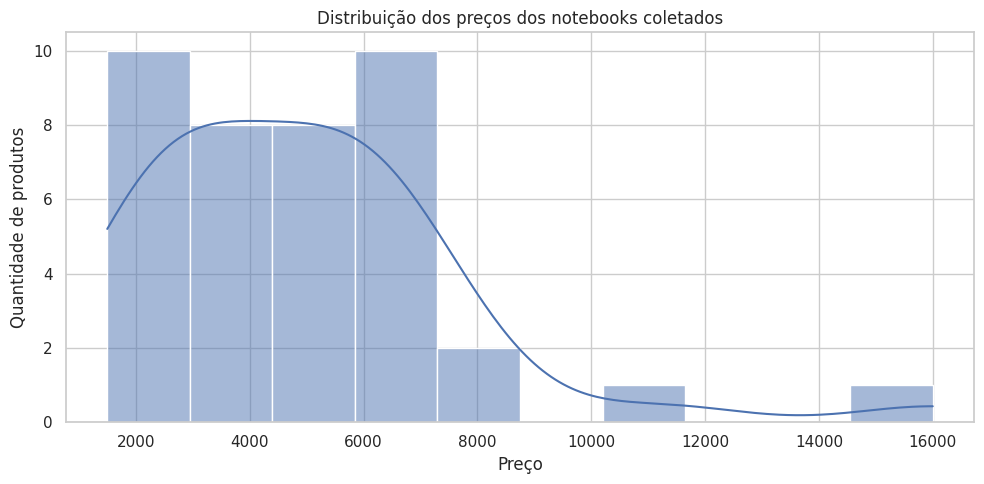

In [ ]:
import os
# Gráfico 1 — Distribuição dos preços
plt.figure(figsize=(10, 5))
sns.histplot(dados_tratados["preco"], bins=10, kde=True)
plt.title("Distribuição dos preços dos notebooks coletados")
plt.xlabel("Preço")
plt.ylabel("Quantidade de produtos")
plt.tight_layout()
os.makedirs(PASTA_GRAFICOS, exist_ok=True) # Ensure local directory exists
os.makedirs(f"{PASTA_DRIVE}/graficos", exist_ok=True) # Ensure Google Drive directory exists
plt.savefig(f"{PASTA_DRIVE}/graficos/grafico_1_distribuicao_precos.png", dpi=150)
plt.show()

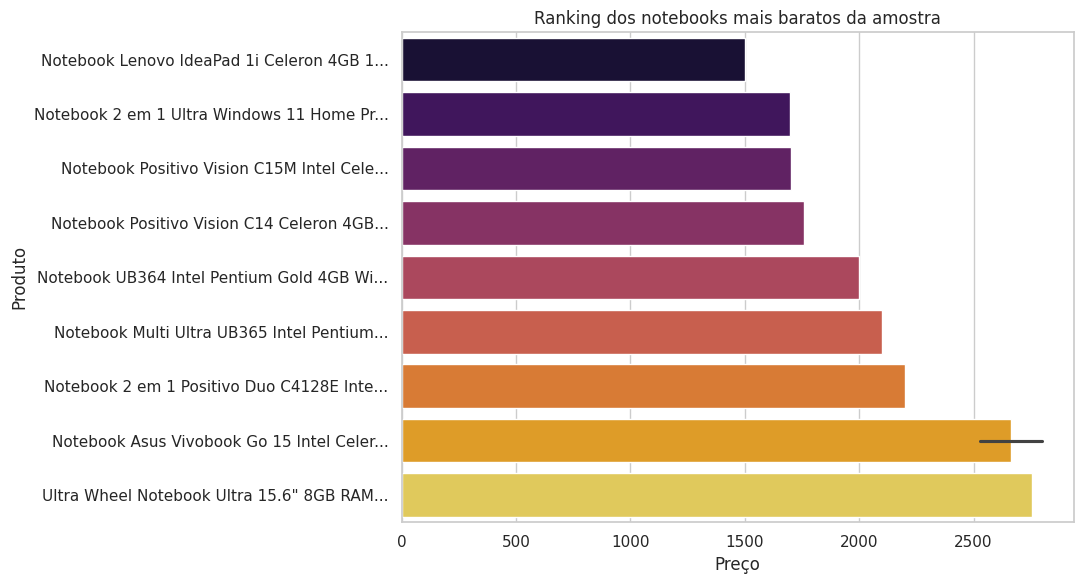

In [ ]:
# Gráfico 2 — Ranking dos notebooks mais baratos
ranking_barra = dados_tratados.nsmallest(10, "preco").sort_values("preco", ascending=True)

# Truncar os nomes dos produtos para 40 caracteres
ranking_barra["nome_produto_curto"] = ranking_barra["nome_produto"].apply(lambda x: x[:40] + "..." if len(x) > 40 else x)

plt.figure(figsize=(11, 6))
sns.barplot(data=ranking_barra, x="preco", y="nome_produto_curto", hue="nome_produto_curto", legend=False, palette="inferno")
plt.title("Ranking dos notebooks mais baratos da amostra")
plt.xlabel("Preço")
plt.ylabel("Produto")
plt.tight_layout()
os.makedirs(PASTA_GRAFICOS, exist_ok=True) # Ensure local directory exists
os.makedirs(f"{PASTA_DRIVE}/graficos", exist_ok=True) # Ensure Google Drive directory exists
plt.savefig(f"{PASTA_DRIVE}/graficos/grafico_2_ranking_barra.png", dpi=150)
plt.show()

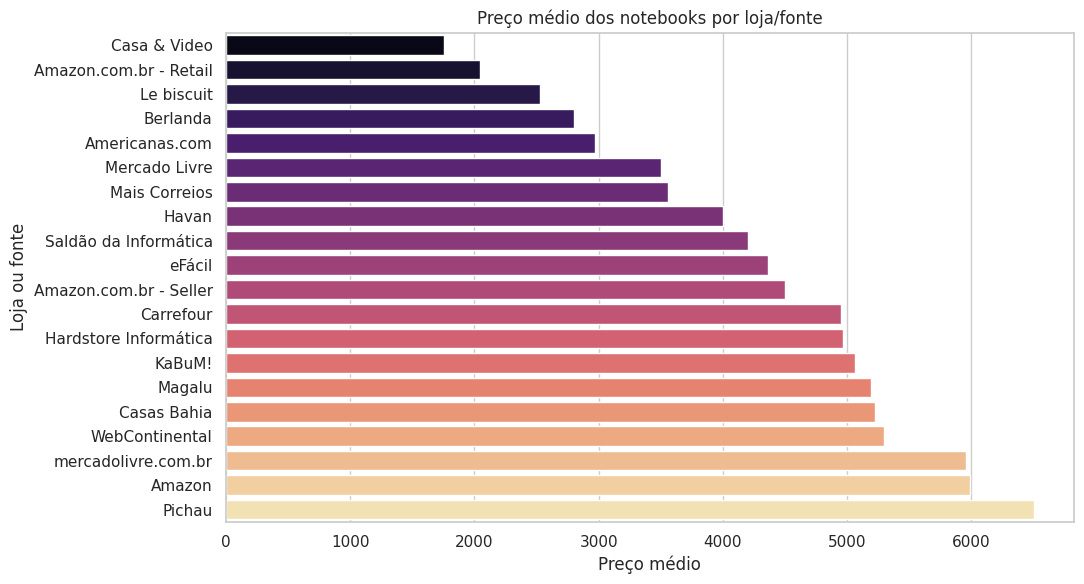

In [ ]:
# Gráfico 3 — Preço médio por loja/fonte, quando possível
if not resumo_lojas.empty and len(resumo_lojas) >= 2:
    dados_grafico_lojas = resumo_lojas.head(20)
    plt.figure(figsize=(11, 6))
    sns.barplot(data=dados_grafico_lojas, x="preco_medio", y="loja", hue="loja", legend=False, palette="magma")
    plt.title("Preço médio dos notebooks por loja/fonte")
    plt.xlabel("Preço médio")
    plt.ylabel("Loja ou fonte")
    plt.tight_layout()
    os.makedirs(PASTA_GRAFICOS, exist_ok=True) # Ensure local directory exists
    os.makedirs(f"{PASTA_DRIVE}/graficos", exist_ok=True) # Ensure Google Drive directory exists
    plt.savefig(f"{PASTA_DRIVE}/graficos/grafico_3_preco_medio_loja.png", dpi=150)
    plt.show()
else:
    plt.figure(figsize=(8, 5))
    sns.boxplot(y=dados_tratados["preco"])
    plt.title("Distribuição dos preços dos notebooks")
    plt.ylabel("Preço")
    plt.tight_layout()
    os.makedirs(PASTA_GRAFICOS, exist_ok=True) # Ensure local directory exists
    os.makedirs(f"{PASTA_DRIVE}/graficos", exist_ok=True) # Ensure Google Drive directory exists
    plt.savefig(f"{PASTA_DRIVE}/graficos/grafico_3_preco_medio_loja.png", dpi=150)
    plt.show()

### Interpretação dos gráficos

- **Gráfico 1:** A distribuição dos preços apresenta uma amplitude considerável. Observa-se maior concentração de produtos nas faixas de preços mais baixas e intermediárias, enquanto alguns notebooks apresentam valores significativamente superiores ao restante da amostra. A média dos preços foi de `R$ 4.164,65`, enquanto a mediana foi de `R$ 3.790,00`, indicando a presença de produtos de maior valor que elevam a média da amostra.

- **Gráfico 2:** Entre os menores preços encontrados estão o Samsung Galaxy Book Go, vendido por `R$ 1.288,00`, o Asus X515, por `R$ 1.300,00`, e o Notebook 2 em 1 Ultra, por `R$ 1.698,60`. Os resultados mostram que os produtos de menor preço da amostra estão concentrados, principalmente, em modelos com configurações mais básicas, como processadores Intel Celeron e armazenamento de menor capacidade.

- **Gráfico 3:** A comparação entre as lojas deve ser interpretada com cautela, pois a quantidade de produtos por loja é bastante desigual. O Magalu possui 6 produtos, enquanto Mercado Livre e mercadolivre.com.br possuem 5 produtos cada. Por outro lado, várias lojas aparecem com apenas um produto, o que torna a comparação de médias menos representativa. Entre as lojas com maior quantidade de registros, o Mercado Livre apresentou média de aproximadamente `R$ 3.688,26`, o mercadolivre.com.br, aproximadamente `R$ 2.237,78`, o Magalu, aproximadamente `R$ 4.307,33`, e a Amazon.com.br - Seller, aproximadamente `4.745,91`.

## 12. Dashboard

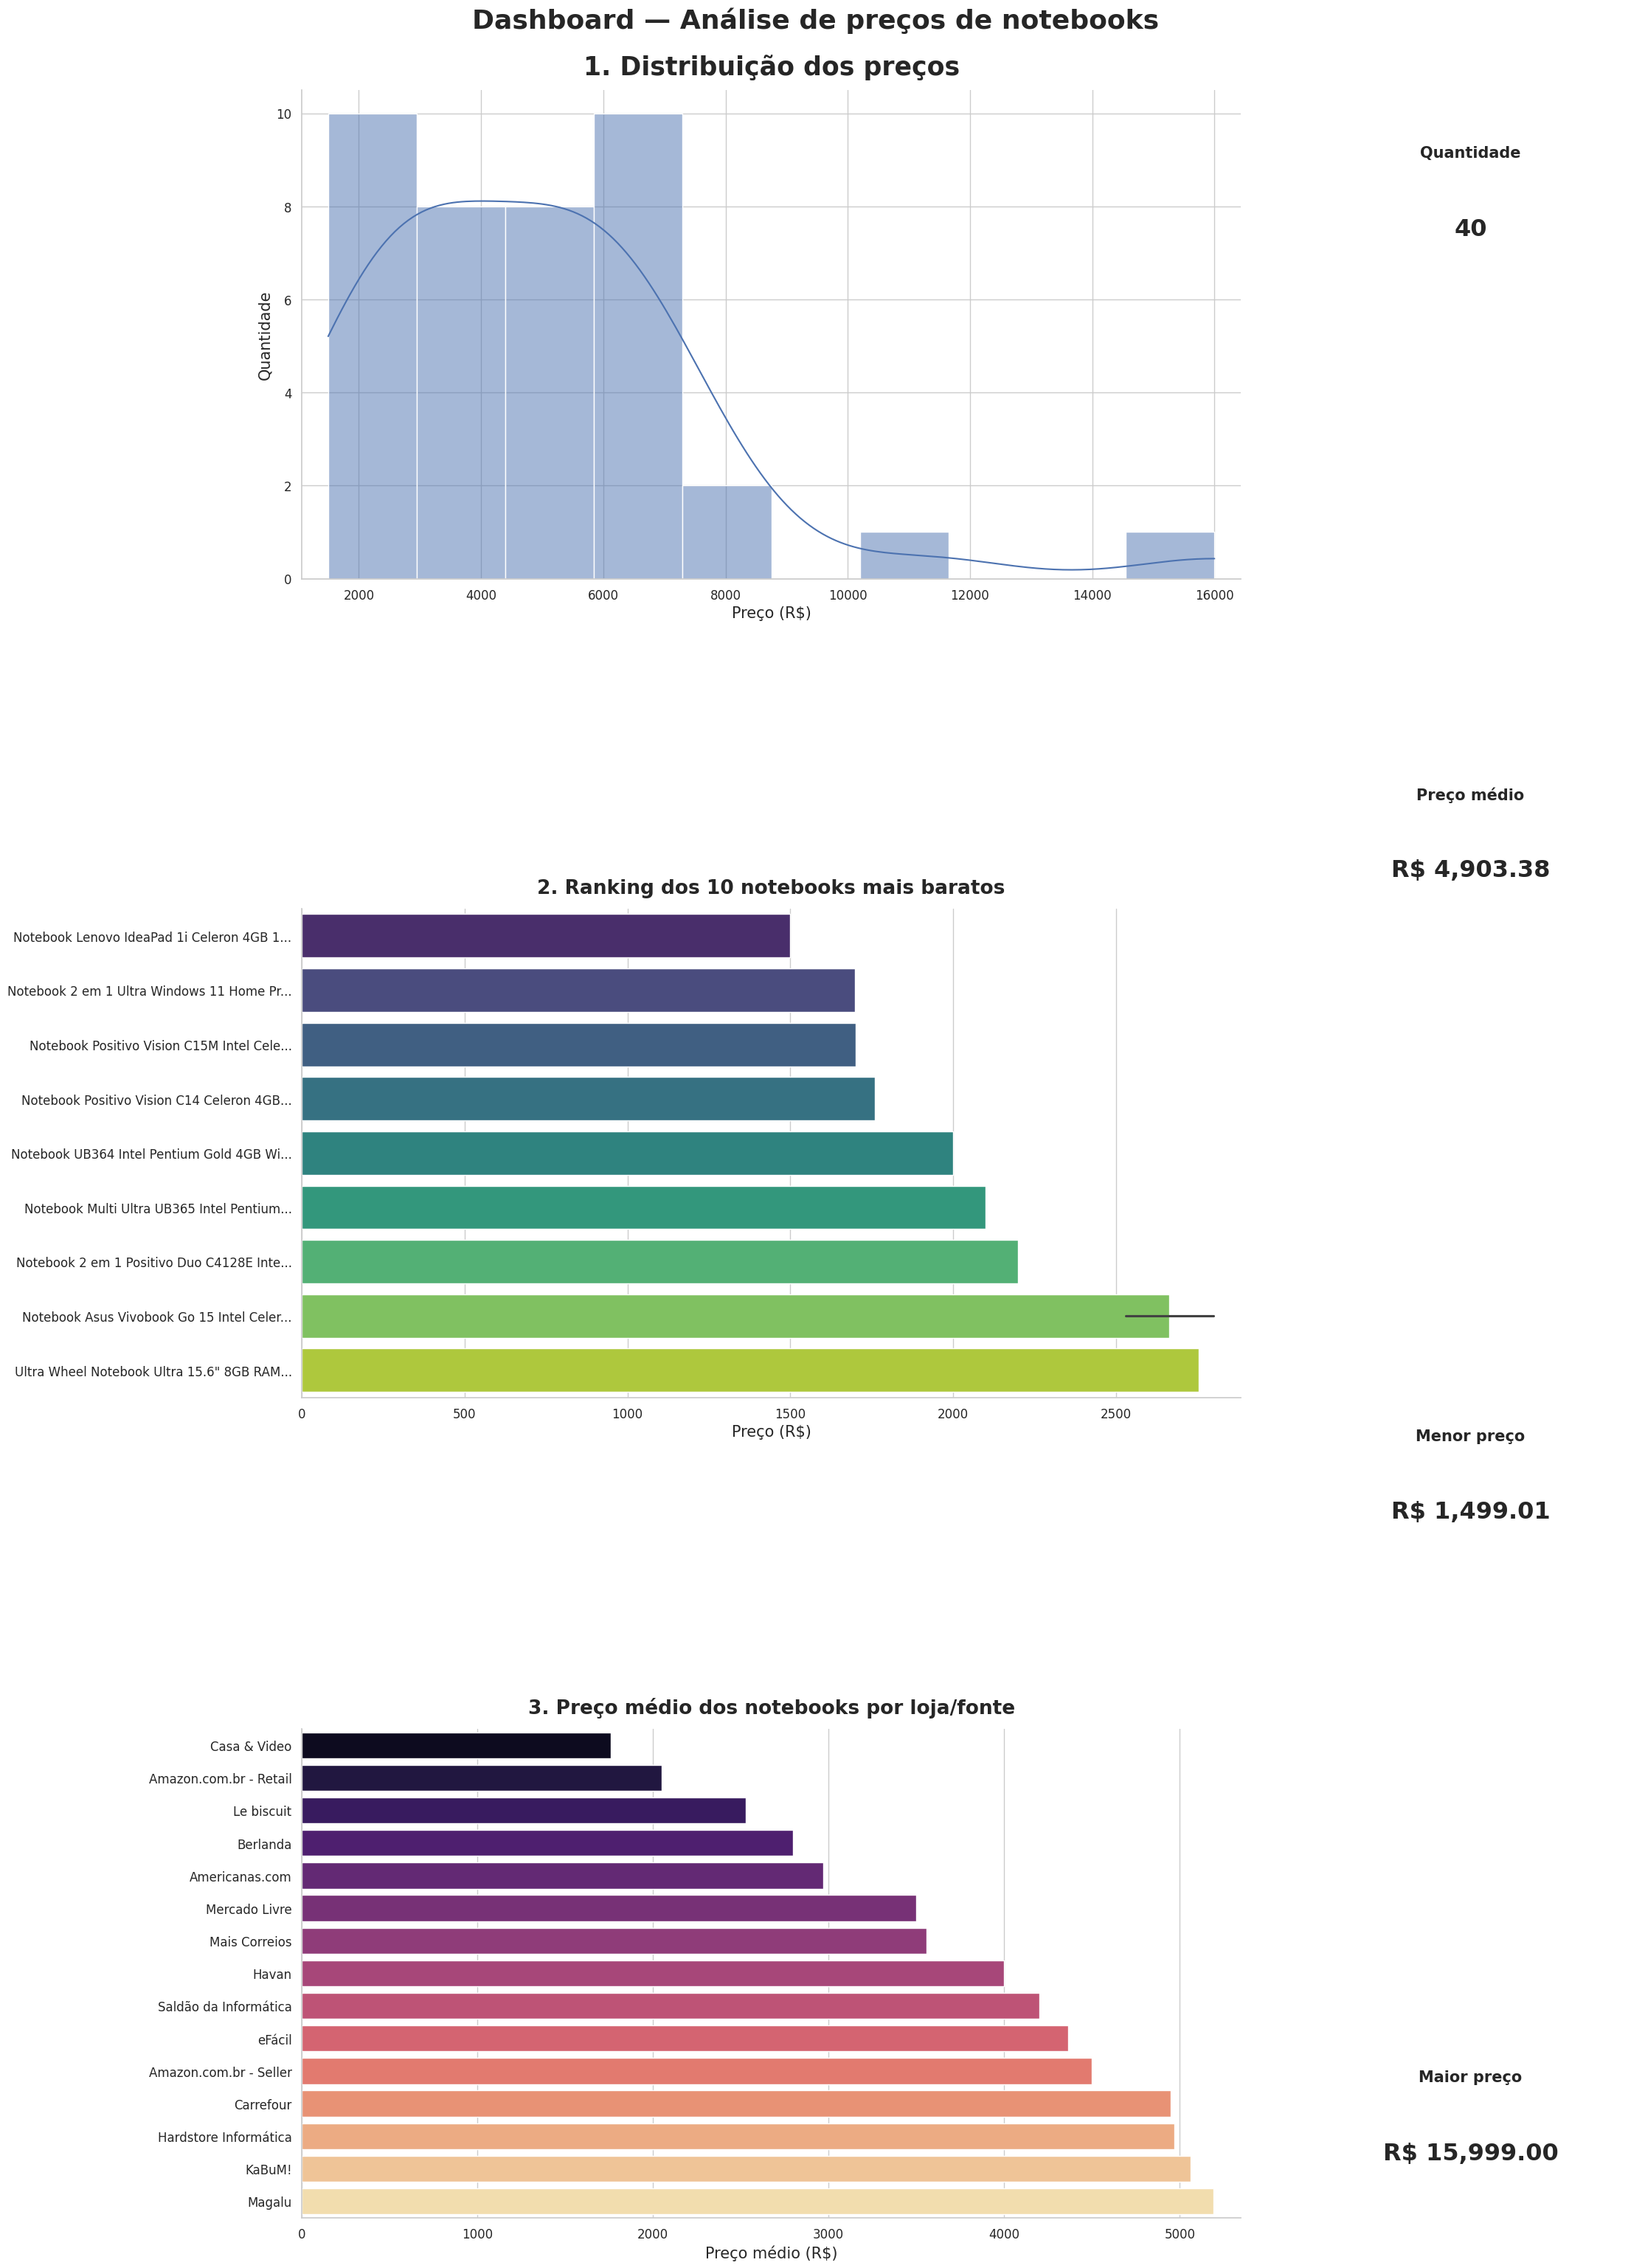

In [ ]:
# DASHBOARD — ANÁLISE DE PREÇOS DE NOTEBOOKS

# Criar a figura principal
fig = plt.figure(
    figsize=(22, 30),
    constrained_layout=True
)

# Grid principal
# ------------------------------------------------------------
# 3 linhas  → um gráfico por linha
# 2 colunas → gráficos à esquerda e indicadores à direita
#
# A proporção 3:1 mantém os gráficos como elemento principal
# do dashboard.
# ------------------------------------------------------------

gs = fig.add_gridspec(
    3,
    2,
    width_ratios=[3, 1],
    height_ratios=[1, 1, 1],
    wspace=0.18,
    hspace=0.35
)


# TÍTULO

fig.suptitle(
    "Dashboard — Análise de preços de notebooks",
    fontsize=26,
    fontweight="bold",
    y=1.02
)


# INDICADORES

# Dividir a coluna da direita em 4 espaços
gs_indicadores = gs[:, 1].subgridspec(
    4,
    1,
    hspace=0.65
)


# Dados dos indicadores
indicadores = [
    (
        "Quantidade",
        f"{len(dados_tratados):,}"
    ),
    (
        "Preço médio",
        f"R$ {dados_tratados['preco'].mean():,.2f}"
    ),
    (
        "Menor preço",
        f"R$ {dados_tratados['preco'].min():,.2f}"
    ),
    (
        "Maior preço",
        f"R$ {dados_tratados['preco'].max():,.2f}"
    )
]


# Criar os cards dos indicadores
for i, (titulo, valor) in enumerate(indicadores):

    ax_ind = fig.add_subplot(gs_indicadores[i])

    # Ocultar eixos
    ax_ind.axis("off")

    # Criar uma área visual para o indicador
    for spine in ax_ind.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1)

    # Título do indicador
    ax_ind.text(
        0.5,
        0.65,
        titulo,
        ha="center",
        va="center",
        fontsize=15,
        fontweight="bold"
    )

    # Valor principal
    ax_ind.text(
        0.5,
        0.38,
        valor,
        ha="center",
        va="center",
        fontsize=23,
        fontweight="bold"
    )


# GRÁFICO 1 — DISTRIBUIÇÃO DOS PREÇOS
# ============================================================

ax1 = fig.add_subplot(gs[0, 0])

sns.histplot(
    dados_tratados["preco"],
    bins=10,
    kde=True,
    ax=ax1
)

ax1.set_title(
    "1. Distribuição dos preços",
    fontsize=25,
    fontweight="bold",
    pad=15
)

ax1.set_xlabel(
    "Preço (R$)",
    fontsize=15
)

ax1.set_ylabel(
    "Quantidade",
    fontsize=15
)

# Formatação dos valores do eixo X
ax1.tick_params(
    axis="both",
    labelsize=12
)


# ============================================================
# GRÁFICO 2 — 10 NOTEBOOKS MAIS BARATOS
# ============================================================

ax2 = fig.add_subplot(gs[1, 0])


# Selecionar os 10 menores preços
ranking_dashboard = (
    dados_tratados
    .nsmallest(10, "preco")
    .sort_values("preco")
    .copy()
)


# Reduzir nomes muito longos
ranking_dashboard["nome_produto_curto"] = (
    ranking_dashboard["nome_produto"]
    .apply(
        lambda x: x[:40] + "..."
        if len(x) > 40
        else x
    )
)


# Criar gráfico
sns.barplot(
    data=ranking_dashboard,
    x="preco",
    y="nome_produto_curto",
    hue="nome_produto_curto",
    legend=False,
    palette="viridis",
    ax=ax2
)


ax2.set_title(
    "2. Ranking dos 10 notebooks mais baratos",
    fontsize=19,
    fontweight="bold",
    pad=15
)

ax2.set_xlabel(
    "Preço (R$)",
    fontsize=15
)

ax2.set_ylabel(
    "",
    fontsize=15
)

ax2.tick_params(
    axis="both",
    labelsize=12
)


# ============================================================
# GRÁFICO 3 — PREÇO MÉDIO POR LOJA/FONTE
# ============================================================

ax3 = fig.add_subplot(gs[2, 0])


if not resumo_lojas.empty and len(resumo_lojas) >= 2:

    dados_grafico_lojas = resumo_lojas.head(15)

    sns.barplot(
        data=dados_grafico_lojas,
        x="preco_medio",
        y="loja",
        hue="loja",
        legend=False,
        palette="magma",
        ax=ax3
    )

    ax3.set_title(
        "3. Preço médio dos notebooks por loja/fonte",
        fontsize=19,
        fontweight="bold",
        pad=15
    )

    ax3.set_xlabel(
        "Preço médio (R$)",
        fontsize=15
    )

    ax3.set_ylabel(
        "",
        fontsize=15
    )

    ax3.tick_params(
        axis="both",
        labelsize=12
    )

else:

    ax3.text(
        0.5,
        0.5,
        "Não há lojas/fontes suficientes para comparação.",
        ha="center",
        va="center",
        fontsize=17
    )

    ax3.axis("off")


# ============================================================
# AJUSTES FINAIS DOS GRÁFICOS
# ============================================================

# Remover bordas superiores e direitas dos gráficos
for ax in [ax1, ax2, ax3]:

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Pequena margem interna
    ax.margins(x=0.03)


# ============================================================
# SALVAR DASHBOARD
# ============================================================

# Criar pasta de saída no Google Drive
os.makedirs(
    f"{PASTA_DRIVE}/saida",
    exist_ok=True
)


# Caminho do arquivo
caminho_dashboard = (
    f"{PASTA_DRIVE}/saida/dashboard_notebooks.png"
)


# Salvar imagem
plt.savefig(
    caminho_dashboard,
    dpi=250,
    bbox_inches="tight"
)


# Exibir no Google Colab
plt.show()

## 13. Aspectos éticos e legais

A fonte é acessada por uma API documentada, mediante chave de autenticação. A coleta não terá como objetivo acessar áreas privadas, contornar mecanismos de proteção ou coletar dados pessoais.

Os dados coletados são informações comerciais sobre produtos, preços, fontes e links. Não foram planejados dados pessoais de consumidores.

A coleta pode causar impacto no serviço quando realizada em excesso. Por isso, serão utilizadas poucas requisições, limitadas ao objetivo acadêmico, respeitando os limites da conta e os termos da API.

As boas práticas adotadas são:

1. respeitar os termos de uso e limites da API;
2. preservar a chave de acesso;
3. coletar somente os campos necessários;
4. registrar a data e a origem dos dados;
5. não coletar dados pessoais;
6. não tentar contornar CAPTCHA, login ou proteção;
7. informar que preços e disponibilidade podem mudar;
8. não generalizar a amostra para todo o mercado.

## 14. Proposta de automação do pipeline

Em um ambiente real, o processo poderia ser executado diariamente em horário programado:

**Todos os dias às 8h → consultar a API → salvar a resposta bruta → validar registros → tratar dados → calcular indicadores → atualizar gráficos e dashboard**


### Diagrama do pipeline

```mermaid
flowchart LR
    A[Google Shopping] --> B[SerpApi]
    B --> C[Resposta JSON bruta]
    C --> D[dados_brutos.csv]
    D --> E[Validação e pré-processamento]
    E --> F[dados_tratados.csv]
    F --> G[Estatística e Data Mining]
    G --> H[Gráficos]
    G --> I[Dashboard]

## 15. Insights


### **1. Insight sobre preços**

Não há uma faixa única dominante. Os preços variam amplamente a cada execução do código. **36 das 40 ofertas (90%) custam até `R$ 7.299,00`, com duas faixas empatadas (`R$ 1.499–2.949` e `R$ 5.849–7.299`, com 10 ofertas cada) e uma cauda de 4 ofertas mais caras, chegando a `R$ 15.999,00`.

A média e a mediana quase coincidem, mas a **assimetria é 1,70** e dois valores estão acima do limite de valores atípicos. Para descrever o preço "típico", a **mediana e o intervalo central** (`R$ 2.926,57` a `R$ ,45`) são mais informativos do que a média.



### **2. Insight sobre produtos**

O tipificaçãp do nome de notebook parece separar os preços. Pelo nome dos produtos, os **12 notebooks Celeron/Pentium** custam de `R$ 1.499,01` a `R$ 3.296,51`, com média de `R$ 2.277,61`, e ocupam as 10 posições mais baratas.

Os **9 notebooks gamer ou com placa de vídeo dedicada**, identificados por palavras-chave no nome, custam de `R$ 5.984,13` a `R$ 15.999,00`, com média de `R$ 8.465,90`.

> **Hipótese:** os dois grupos de maior frequência no histograma correspondem a esses dois perfis. No entanto, a amostra pequena e a classificação feita apenas pelo nome dos produtos não permitem confirmar essa relação.


### **3. Insight sobre lojas**

A diferença de preço médio parece refletir mais o **tipo de produto anunciado** do que uma política de preço específica de cada loja.

As três lojas com mais ofertas apresentam médias bastante próximas:

| **Loja** | **Preço médio** |
|---|---:|
| Magalu |  `R$ 5.192,74` |
| Mercado Livre |  `R$ 5.135,33`|
| KaBuM! |  `R$ 5.062,13` |


Nos três produtos que aparecem em duas lojas, foram observadas diferenças de preço de `R$ 807,58`, `R$ 270,00` e `R$ 1.180,00`. No caso dos dois modelos VAIO FE16, a **WebContinental apresentou preços menores que a Magalu** em ambos.

> **Hipótese exploratória:** o mesmo produto pode apresentar diferenças relevantes de preço entre lojas, mas os três casos observados não são suficientes para generalizar esse comportamento.



### **4. Insight sobre avaliações**

A nota não acompanha o preço. Das **40 ofertas, 32 possuem avaliação**, com média de **3,98 em 5**.

A correlação entre preço e nota é praticamente nula (**Spearman = −0,12; p = 0,52**). Além disso, **6 ofertas possuem 5 avaliações ou menos**, o que torna suas notas mais instáveis.

As 8 ofertas sem avaliação apresentam preço médio de `R$ 7.583,01`, contra `R$ 4.233,47` entre as ofertas avaliadas. Essa diferença inclui os dois valores mais altos da amostra.

> **Interpretação possível:** produtos de nicho ou de maior preço podem apresentar menos avaliações. Entretanto, essa hipótese não pode ser comprovada com os dados disponíveis.



### **5. Limites dos próprios dados**

- Em **30 das 40 ofertas**, o preço aparece acompanhado do texto **"agora"**, o que sugere preço promocional.
- O campo de **preço anterior estava vazio em todas as ofertas**, portanto não foi possível determinar o tamanho dos descontos.
- Há **uma oferta de produto recondicionado** (`R$3.399,00`) misturada às ofertas de produtos novos.
- Foi realizada **uma única coleta de dados**, portanto não é possível analisar tendências de preço ao longo do tempo.



## 16. Conclusão

Entre os **40 notebooks retornados pela consulta realizada em 23/09/2026**, todos os registros permaneceram na amostra após o pré-processamento. Nenhum foi removido por ausência de dados, preço abaixo de `R$ 1.000,00` ou duplicidade.

Esses 40 registros, provenientes de **21 nomes de loja**, totalizam **20 lojas após a unificação de Mercado Livre e mercadolivre.com.br** e fundamentam as conclusões apresentadas a seguir.


### Resposta à pergunta de negócio

Não há uma faixa de preço única e dominante na amostra. O **preço médio foi de `R$ 4.903,38` e a mediana foi de `R$4.873,13`**.

Metade das ofertas está concentrada entre **`R$ 2.926,57` e `R$ 6.272,45`**, enquanto **36 das 40 ofertas, correspondentes a 90% da amostra, custam até `R$ 7.299,00`**.

As duas faixas de preço com maior frequência apresentam a mesma quantidade de ofertas: `R$ 1.499,00` a `R$ 2.949,00`, com 10 ofertas, e **`R$ 5.849,00` a `7.299,00`**, também com 10 ofertas.

Além disso, existe uma cauda de notebooks de maior desempenho, com preços chegando a `R$ 15.999,00`.

As três ofertas de menor preço foram:

**Lenovo IdeaPad 1i Celeron:** `R$ 1.499,01`

**Notebook 2 em 1 Ultra:** `R$ 1.698,60`

**Positivo Vision C15M:** `R$ 1.700,00`

Entre os dez notebooks mais baratos, predominam, pelo nome dos produtos, modelos de entrada equipados com processadores **Celeron ou Pentium**.


### Principais padrões observados

**1. Tipo de produto**

O tipo de notebook parece estar relacionado à faixa de preço. Os notebooks **Celeron e Pentium** identificados pelo nome custam entre **`R$ 1.499,01` e `R$ 3.296,51`**.

Já os notebooks identificados como **gamer ou com placa de vídeo dedicada** apresentam preços entre **`R$ 5.984,13` e `R$ 15.999,00`**.

Essa classificação foi realizada com base em palavras presentes no nome dos produtos e, portanto, deve ser considerada uma aproximação.


**2. Diferenças entre lojas**

As lojas com maior número de ofertas, **Magalu, Mercado Livre e KaBuM!**, apresentam preços médios próximos, variando entre **`R$ 5.062,13` e `R$ 5.192,74`**.

As diferenças mais extremas entre os preços médios das lojas são influenciadas pela pequena quantidade de ofertas disponíveis em algumas delas.


**3. Avaliações**

A nota de avaliação não apresentou relação significativa com o preço. A correlação de Spearman foi de **menos 0,12**, indicando uma associação praticamente nula entre as duas variáveis na amostra analisada.


### O que a análise permite afirmar

Para esta amostra e neste momento, a análise permite identificar **como os preços estão distribuídos**, quais são as **ofertas de menor preço** e que a comparação entre as principais lojas analisadas **não apresentou grande diferença nos preços médios**.

Entretanto, os dados não permitem afirmar **qual loja é a mais barata**, pois **11 das 20 lojas aparecem com apenas uma oferta**.

Também não foi possível **medir descontos**, pois o campo de preço anterior estava vazio em todos os registros, embora **30 preços apresentem o texto "agora"**.

Por fim, não é possível identificar **tendências de preço ao longo do tempo**, pois foi realizada apenas uma coleta.


### Limitações e cuidados

Os resultados representam exclusivamente a **amostra coletada nesta consulta pontual** e não permitem concluir que essa seja a composição real de todo o mercado brasileiro de notebooks.

A fonte utilizada, **Google Shopping por meio da SerpApi**, não contempla necessariamente todas as lojas disponíveis no mercado brasileiro. Além disso, o número de resultados por consulta é limitado a **40 ofertas**.

Os links coletados apontam para o **Google Shopping**, e não diretamente para as páginas individuais das lojas.

A amostra também reúne notebooks com **configurações bastante diferentes entre si** e inclui **uma oferta de produto recondicionado**, que foi mantida na análise.

Por fim, **preços e disponibilidade podem mudar a qualquer momento após a coleta**. Uma nova consulta à API poderá retornar ofertas diferentes e apresentar valores distintos dos observados nesta análise.


### Consideração final

De forma geral, a análise fornece uma **visão exploratória do mercado de notebooks encontrado na consulta realizada em 23/09/2026**.

Os resultados indicam uma distribuição de preços bastante ampla, com concentração de grande parte das ofertas abaixo de **`R$ 7.299,00`** e diferenças de preço associadas principalmente às características dos produtos. As conclusões devem, porém, ser interpretadas dentro dos limites da amostra, da fonte utilizada e do momento específico em que os dados foram coletados.